# 07 - Synthetic clickstream data

Goal: create the page-view data the LSTM needs, because the paper's data is private.

Replaces: the dataset of paper Section 3.1. Our professor approved synthetic data.

Needs: nothing. Writes data/synthetic_clickstream.csv, which notebook 08 reads.

Expected run time: under 1 minute.

Status: executed

### This data is SYNTHETIC

We made this data ourselves. Accuracy values in notebook 08 are therefore not comparable with the paper's numbers. Only the method is replicated.

## 1. Setup
All the numbers of the generator are in this cell. They are our own choices. We tuned them so the totals land near the paper's totals. Our first numbers gave too weak a signal, and in a side check almost no score could pass the higher thresholds of Figure 2. So we made exits differ more by page type, and we made administrative and cart pages more likely to be followed by the same type. Nothing is trained, so N_REPEATS is not used.

In [1]:
import os
os.environ["LOKY_MAX_CPU_COUNT"] = "4"  # Windows: set before the other imports

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from utils import COLOURS, SEED, set_style

N_REPEATS = 10  # paper uses 100 (not used here: nothing is trained)
set_style()

PAGES = ["product", "administrative", "informational", "cart"]
N_VISITORS = 3500
N_SESSIONS = 9800
MIN_VIEWS = 4  # every session has at least this many page views

# Probability of the first page, then of the next page given the current page (rows sum to 1).
START = [0.70, 0.10, 0.15, 0.05]
NEXT_PAGE = np.array([
    [0.84, 0.04, 0.06, 0.06],  # from product
    [0.35, 0.45, 0.05, 0.15],  # from administrative
    [0.65, 0.08, 0.24, 0.03],  # from informational
    [0.30, 0.15, 0.05, 0.50],  # from cart
])

# Time on page: log-normal, set by a median in seconds and a spread for each page type.
MEDIAN_SECONDS = [40, 12, 30, 12]
SPREAD = [1.0, 0.9, 1.0, 0.8]

# Chance of leaving after a page: higher after cart and administrative pages,
# and multiplied when the visitor stayed only a very short time.
EXIT_PROB = [0.009, 0.160, 0.050, 0.300]
SHORT_SECONDS = 5
SHORT_FACTOR = 3

## 2. The generator
Each session is a Markov chain, which means the next page depends only on the current page. From page 4 onwards, the visitor may leave after each page, with the probability set above. A very short stay makes leaving more likely.

In [2]:
def make_session(rng):
    """Generate one session as a list of (page number, seconds)."""
    views = []
    page = rng.choice(4, p=START)
    while True:
        seconds = rng.lognormal(np.log(MEDIAN_SECONDS[page]), SPREAD[page])
        views.append((page, seconds))

        exit_prob = EXIT_PROB[page]
        if seconds < SHORT_SECONDS:
            exit_prob = exit_prob * SHORT_FACTOR
        if len(views) >= MIN_VIEWS and rng.random() < exit_prob:
            return views
        page = rng.choice(4, p=NEXT_PAGE[page])


def make_data(seed):
    """Generate all sessions and give each one to a visitor."""
    rng = np.random.default_rng(seed)
    # Every visitor gets one session first; the remaining sessions go to random visitors.
    visitors = np.concatenate([np.arange(N_VISITORS),
                               rng.integers(0, N_VISITORS, N_SESSIONS - N_VISITORS)])
    rows = []
    for session_id, visitor_id in enumerate(visitors):
        for step, (page, seconds) in enumerate(make_session(rng), start=1):
            rows.append((visitor_id, session_id, step, PAGES[page], round(seconds, 2)))
    return pd.DataFrame(rows, columns=["visitor_id", "session_id", "step", "page_type", "seconds"])

## 3. Generate and save
We print our totals next to the paper's.

In [3]:
clicks = make_data(SEED)
clicks.to_csv("data/synthetic_clickstream.csv", index=False)

lengths = clicks.groupby("session_id")["step"].max()
totals = pd.DataFrame({
    "Synthetic": [clicks["visitor_id"].nunique(), clicks["session_id"].nunique(), len(clicks)],
    "Paper": [3500, 9800, 185000],
}, index=["Visitors", "Sessions", "Page views"])
print(totals)
print("Shortest session:", lengths.min(), "| mean:", round(lengths.mean(), 1), "| longest:", lengths.max())
clicks.head()

            Synthetic   Paper
Visitors         3500    3500
Sessions         9800    9800
Page views     184409  185000
Shortest session: 4 | mean: 18.8 | longest: 156


,visitor_id,session_id,step,page_type,seconds
0,0,0,1,product,7.12
1,0,0,2,product,114.08
2,0,0,3,product,13.20
3,0,0,4,product,23.72
4,0,0,5,product,12.52


We are close to the paper's totals. Visitors (3,500) and sessions (9,800) match exactly, and we have 184,409 page views against 185,000.

## 4. Session length
This chart shows how many page views each session has. Look at the left edge and the long right tail.

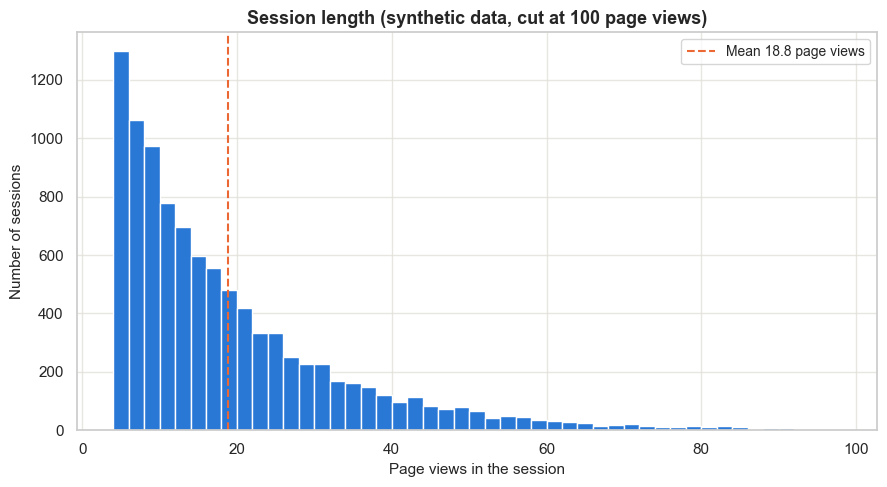

In [4]:
fig, ax = plt.subplots()
ax.hist(lengths, bins=range(4, 100, 2), color=COLOURS[0], edgecolor="white")
ax.axvline(lengths.mean(), color=COLOURS[1], linestyle="--", label=f"Mean {lengths.mean():.1f} page views")
ax.set_title("Session length (synthetic data, cut at 100 page views)")
ax.set_xlabel("Page views in the session")
ax.set_ylabel("Number of sessions")
ax.legend()
plt.tight_layout()
plt.show()

Most sessions are short and a few are very long. The mean is 18.8 page views. The shortest is 4, as we required, and the longest is 156.

## 5. Page types and time on page
These two charts show how often each page type appears and how long visitors stay on it.

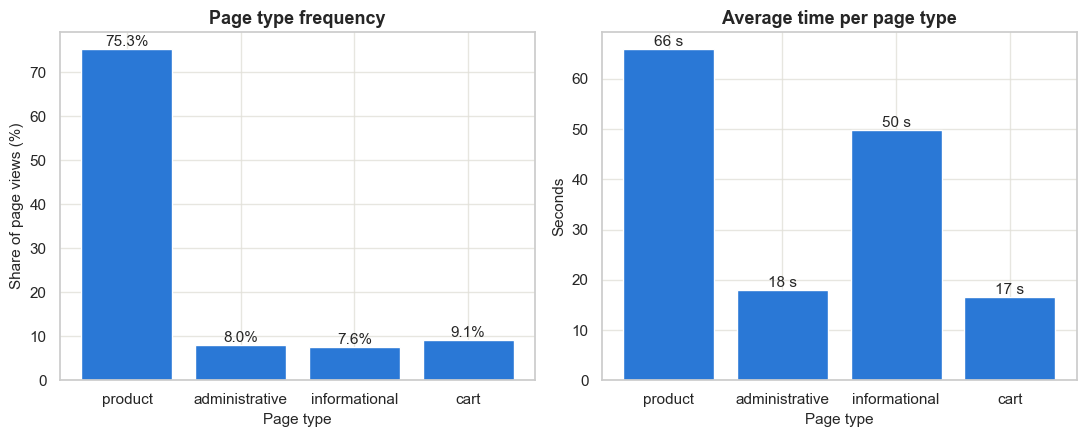

In [5]:
freq = clicks["page_type"].value_counts(normalize=True).reindex(PAGES) * 100
mean_time = clicks.groupby("page_type")["seconds"].mean().reindex(PAGES)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
bars = axes[0].bar(PAGES, freq.values, color=COLOURS[0])
axes[0].bar_label(bars, fmt="%.1f%%")
axes[0].set_title("Page type frequency")
axes[0].set_xlabel("Page type")
axes[0].set_ylabel("Share of page views (%)")
bars = axes[1].bar(PAGES, mean_time.values, color=COLOURS[0])
axes[1].bar_label(bars, fmt="%.0f s")
axes[1].set_title("Average time per page type")
axes[1].set_xlabel("Page type")
axes[1].set_ylabel("Seconds")
plt.tight_layout()
plt.show()

Product pages make up 75.3% of views, cart 9.1%, administrative 8.0% and informational 7.6%. Visitors stay longest on product pages (66 seconds on average) and shortest on cart pages (17 seconds). These numbers come from our own choices, not from the paper, which does not report them.

## 6. The signal the LSTM can learn
This chart shows the chance that a session ends right after a page, by page type and time on page. We count only steps 4 and later, because leaving is not allowed earlier. Compare the page types first, and then the two colours.

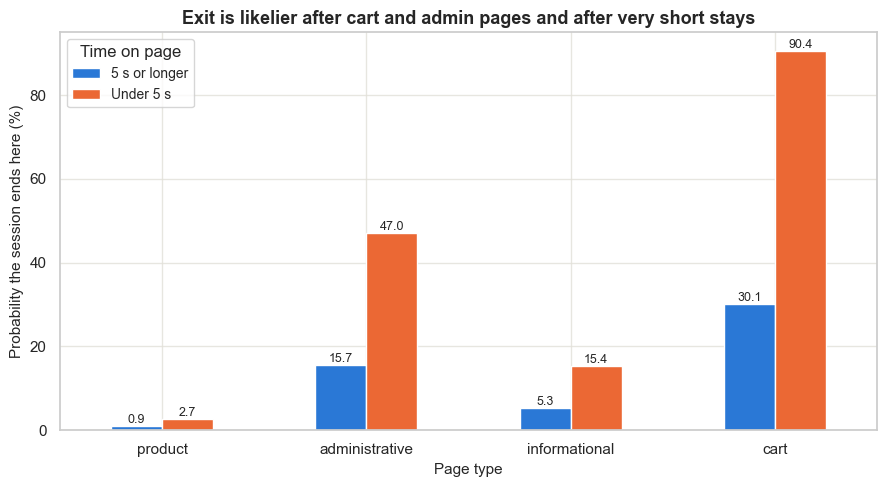

                5 s or longer  Under 5 s
page_type                               
product                   0.9        2.7
administrative           15.7       47.0
informational             5.3       15.4
cart                     30.1       90.4


In [6]:
last_step = clicks["session_id"].map(lengths)
eligible = clicks[clicks["step"] >= MIN_VIEWS].copy()
eligible["ended"] = eligible["step"] == last_step[eligible.index]
eligible["short"] = eligible["seconds"] < SHORT_SECONDS

end_rate = eligible.groupby(["page_type", "short"])["ended"].mean().unstack().reindex(PAGES) * 100
end_rate.columns = [f"{SHORT_SECONDS} s or longer", f"Under {SHORT_SECONDS} s"]

ax = end_rate.plot(kind="bar", color=COLOURS[:2], rot=0)
for container in ax.containers:
    ax.bar_label(container, fmt="%.1f", fontsize=9)
ax.set_title("Exit is likelier after cart and admin pages and after very short stays")
ax.set_xlabel("Page type")
ax.set_ylabel("Probability the session ends here (%)")
ax.legend(title="Time on page")
plt.tight_layout()
plt.show()
print(end_rate.round(1))

The chance of a session ending is 0.9% after a product page and 30.1% after a cart page. It roughly triples after a stay under 5 seconds, to 2.7% and 90.4%. The very high cart value is our own choice, made on purpose so the signal is clear. It is not a fact about real shoppers.

## 7. Key takeaways
This data is SYNTHETIC, so accuracy values in notebook 08 are not comparable with the paper's numbers. Only the method is replicated.

The totals are close to the paper: 3,500 visitors, 9,800 sessions and 184,409 page views against 185,000. Sessions have a mean of 18.8 page views, a minimum of 4 and a maximum of 156. The page mix and the exit chances are our own choices.

The signal is what we built in. We chose the generator's numbers ourselves, so any similarity between notebook 08's accuracy and the paper's comes from those choices, and it is not evidence that we replicated the paper.

Exit and next page depend only on the current page, so earlier pages add no information. This means the LSTM has little advantage over simpler models here. Real visitors may behave differently.